In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix

In [2]:
data = pd.read_csv('Telco-Customer-Churn.csv')

In [3]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
print(data.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [8]:
print(data['TotalCharges'].unique()[:20])
print(data['TotalCharges'].str.strip().eq('').sum())

<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',  '587.45',   '326.8',  '5681.1',  '5036.3',
 '2686.05', '7895.15', '1022.95', '7382.25',  '528.35',  '1862.9']
Length: 20, dtype: str
11


In [9]:
data['TotalCharges'] = pd.to_numeric(
    data['TotalCharges'].str.strip(),
    errors='coerce'
)

In [10]:
print(data['TotalCharges'].isnull().sum())
print(data['TotalCharges'].dtype)

11
float64


In [11]:
data[data['TotalCharges'].isnull()]

data['TotalCharges'] = data['TotalCharges'].fillna(0)

In [12]:
data = data.drop(['customerID'], axis=1)

In [13]:
for col in data.select_dtypes(include='str').columns:
    print(col, data[col].unique())

gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract <StringArray>
['Month-to-month', 'One year', 'Two year']
Le

In [14]:
data['gender'] = ([1 if each == 'Male' else 0 for each in data['gender'] ])
data['Partner'] = ([1 if each == 'Yes' else 0 for each in data['Partner']])
data['Dependents'] = ([1 if each == 'Yes' else 0 for each in data['Dependents'] ])
data['PhoneService'] = ([1 if each == 'Yes' else 0 for each in data['PhoneService']])
data['PaperlessBilling'] = ([1 if each == 'Yes' else 0 for each in data['PaperlessBilling']])

In [15]:
data = pd.get_dummies(data, columns=['InternetService'])
data = pd.get_dummies(data, columns=['Contract'])
data = pd.get_dummies(data, columns=['MultipleLines'])
data = pd.get_dummies(data, columns=['OnlineSecurity'])
data = pd.get_dummies(data, columns=['OnlineBackup'])
data = pd.get_dummies(data, columns=['DeviceProtection'])
data = pd.get_dummies(data, columns=['TechSupport'])
data = pd.get_dummies(data, columns=['StreamingTV'])
data = pd.get_dummies(data, columns=['StreamingMovies'])
data = pd.get_dummies(data, columns=['PaymentMethod'])

In [16]:
print(data.columns)

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'OnlineSecurity_No', 'OnlineSecurity_No internet service',
       'OnlineSecurity_Yes', 'OnlineBackup_No',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No',
       'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMetho

In [17]:
print(data.dtypes)
print(data.isnull().sum().sum())
print(data.shape)

gender                                       int64
SeniorCitizen                                int64
Partner                                      int64
Dependents                                   int64
tenure                                       int64
PhoneService                                 int64
PaperlessBilling                             int64
MonthlyCharges                             float64
TotalCharges                               float64
Churn                                          str
InternetService_DSL                           bool
InternetService_Fiber optic                   bool
InternetService_No                            bool
Contract_Month-to-month                       bool
Contract_One year                             bool
Contract_Two year                             bool
MultipleLines_No                              bool
MultipleLines_No phone service                bool
MultipleLines_Yes                             bool
OnlineSecurity_No              

In [18]:
data['Churn'] = [1 if each == 'Yes' else 0 for each in data['Churn']]

In [19]:
x = data.drop('Churn' , axis=1)
y = data['Churn']

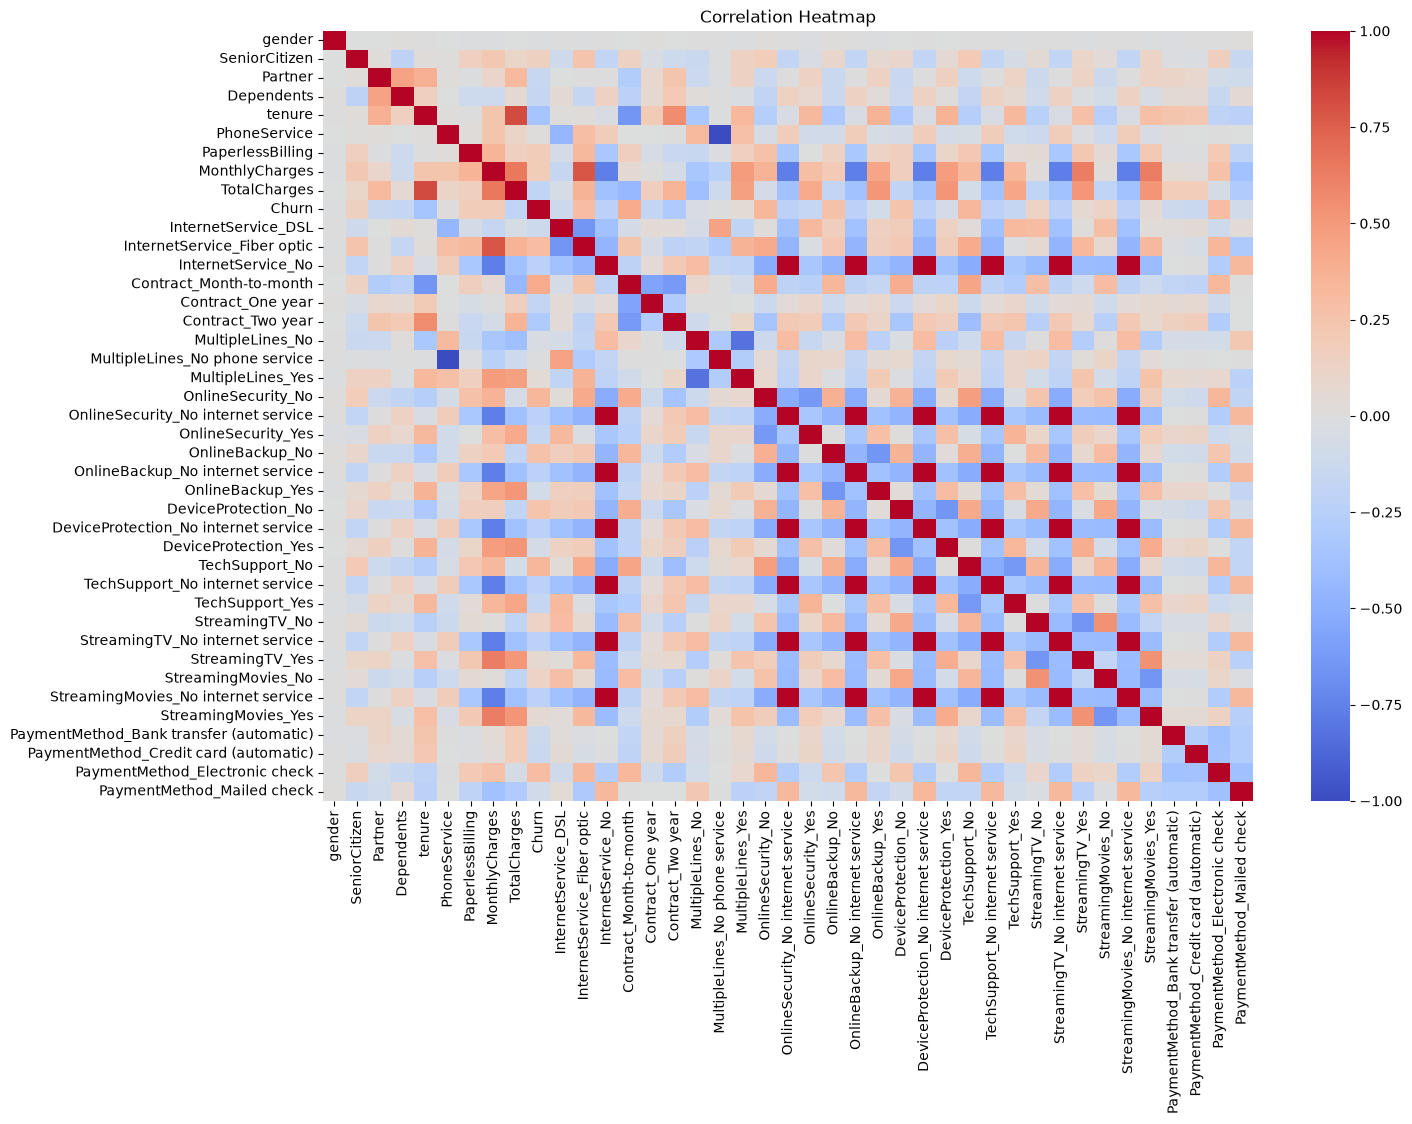

In [20]:
plt.figure(figsize=(15, 10))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=False,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

In [21]:
churn_corr = data.corr(numeric_only=True)['Churn']

churn_corr = churn_corr.drop('Churn')

print(churn_corr.sort_values(ascending=False))

Contract_Month-to-month                    0.405103
OnlineSecurity_No                          0.342637
TechSupport_No                             0.337281
InternetService_Fiber optic                0.308020
PaymentMethod_Electronic check             0.301919
OnlineBackup_No                            0.268005
DeviceProtection_No                        0.252481
MonthlyCharges                             0.193356
PaperlessBilling                           0.191825
SeniorCitizen                              0.150889
StreamingMovies_No                         0.130845
StreamingTV_No                             0.128916
StreamingTV_Yes                            0.063228
StreamingMovies_Yes                        0.061382
MultipleLines_Yes                          0.040102
PhoneService                               0.011942
gender                                    -0.008612
MultipleLines_No phone service            -0.011942
MultipleLines_No                          -0.032569
DeviceProtec

In [22]:
X_train, X_test, y_train, y_test = train_test_split(x, y)

In [23]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [24]:
x.select_dtypes(include=['object', 'str']).columns

Index([], dtype='str')

In [25]:
model = LogisticRegression(max_iter=10000)

model.fit(X_train, y_train)

out = model.predict(X_test)
out

array([1, 0, 0, ..., 0, 0, 1], shape=(1761,))

In [26]:
models = [LogisticRegression(), DecisionTreeClassifier(), KNeighborsClassifier()]

for i in range(3):
    models[i].max_iter = 1000
    models[i].max_depth = 5

    models[i].fit(X_train, y_train)

    print(models[i])
    print('training ROC AUC:', metrics.roc_auc_score(y_train, models[i].predict_proba(X_train)[:, 1]))

    print('test ROC AUC:', metrics.roc_auc_score(y_test, models[i].predict_proba(X_test)[:, 1]))

    print('  ')

    y_pred = models[i].predict(X_test)
    print(metrics.confusion_matrix(y_test, y_pred))

LogisticRegression(max_iter=1000)
training ROC AUC: 0.849041664281195
test ROC AUC: 0.8437744394932225
  
[[1175  123]
 [ 210  253]]
DecisionTreeClassifier(max_depth=5)
training ROC AUC: 0.8560620156575021
test ROC AUC: 0.8145527094350172
  
[[1125  173]
 [ 203  260]]
KNeighborsClassifier()
training ROC AUC: 0.8943047047373265
test ROC AUC: 0.7676488500334457
  
[[1086  212]
 [ 219  244]]


In [27]:
Des = DecisionTreeClassifier()
scores = cross_val_score(
    Des,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

print("Scores:", scores)
print("Mean ROC AUC:", scores.mean())

Scores: [0.66034184 0.66111187 0.64139594 0.67557341 0.65505453]
Mean ROC AUC: 0.6586955180724796
